# Customer purchase patterns
This notebook reviews the training partition. The source workbook is unchanged. Future labels are shown only for training-customer analysis.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data = pd.read_parquet(root / 'data/processed/customers.parquet')
train = data[data['split'] == 'train']
display(train[['recency','frequency','monetary','churn','clv_90d']].describe())

,recency,frequency,monetary,churn,clv_90d
count,3656.000000,3656.000000,3656.000000,3656.000000,3656.000000
mean,203.667357,5.675328,2527.057659,0.571937,484.958671
std,170.504792,11.408515,11378.915196,0.494866,2669.053524
min,0.283333,1.000000,1.550000,0.000000,-60.900000
25%,49.561111,1.000000,310.807500,0.000000,0.000000
50%,160.631944,3.000000,746.490000,1.000000,0.000000
75%,316.445833,6.000000,2047.232500,1.000000,416.600000
max,638.549306,278.000000,451866.970000,1.000000,117634.530000


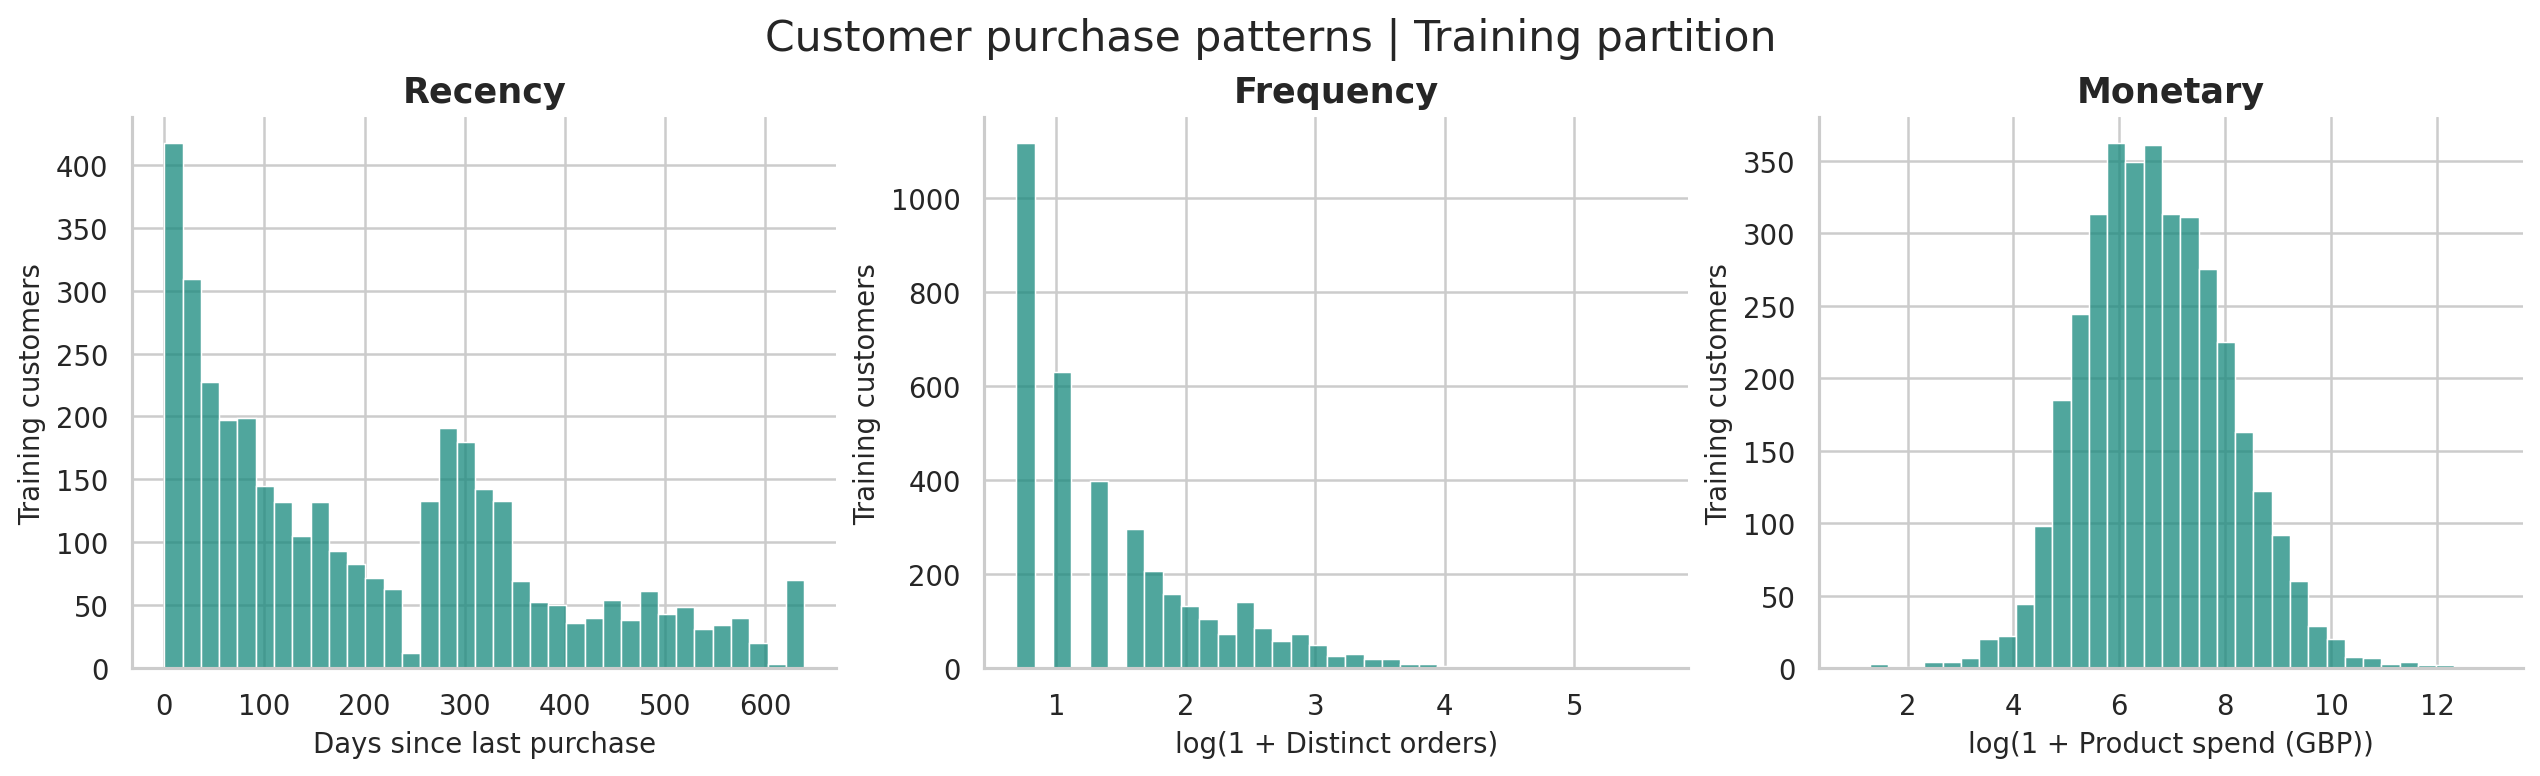

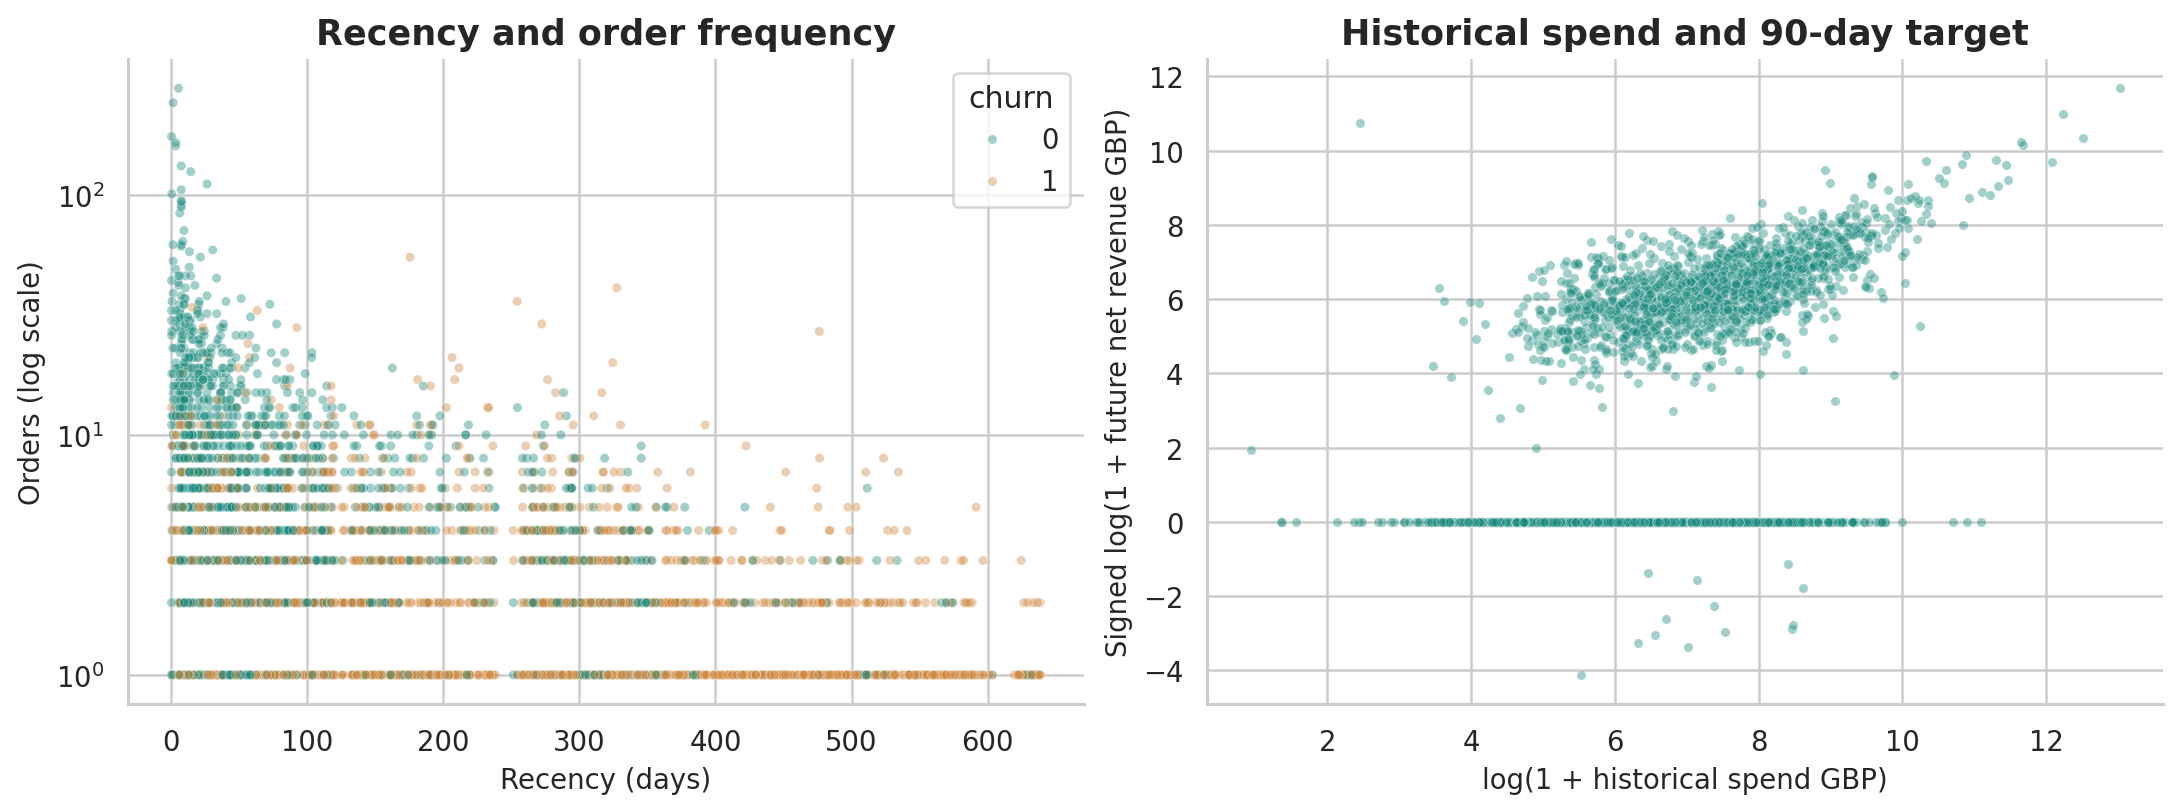

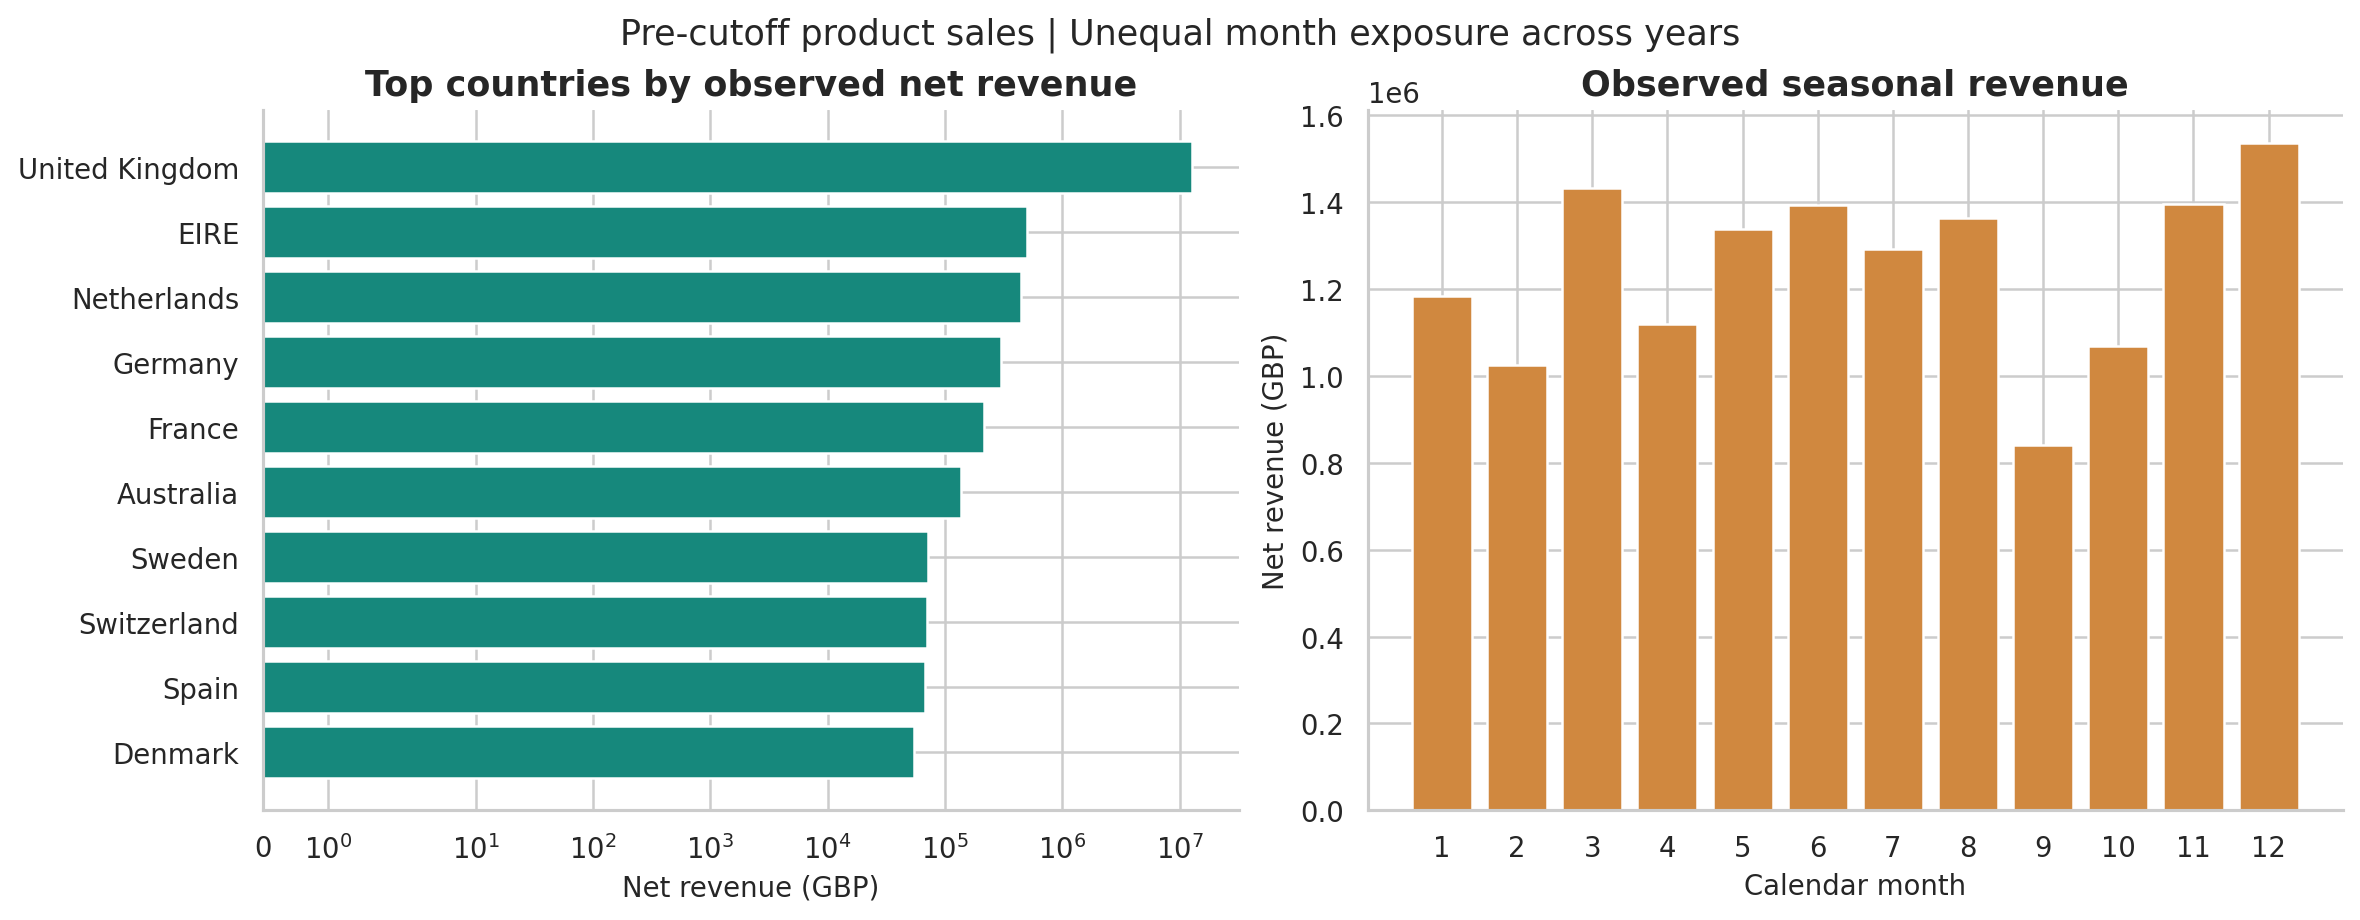

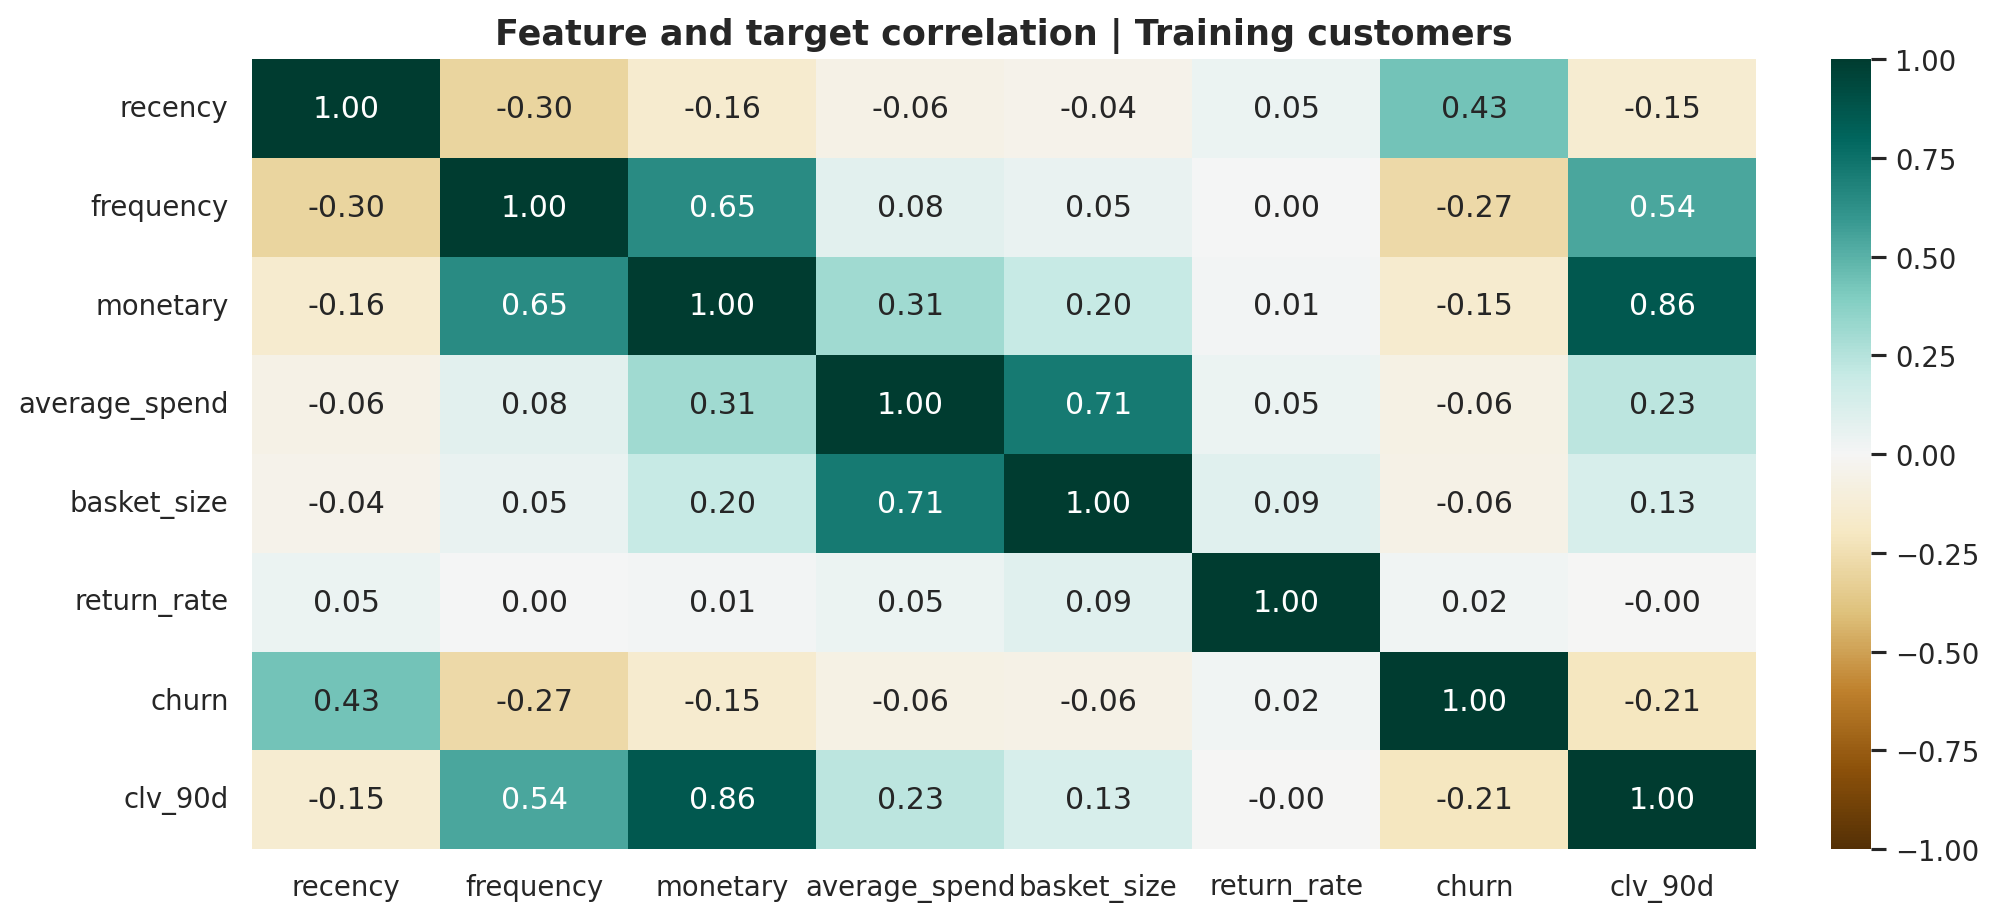

,feature,vif
0,seasonal_concentration,3.488325
1,recency,3.178915
2,tenure,3.027081
3,frequency,2.268652
4,average_spend,2.248955
5,basket_size,2.073739
6,monetary,1.986379
7,affinity_home,1.302295
8,gap_variance,1.265467
9,affinity_kitchen,1.224355


In [2]:
display(Image(filename=str(root / 'docs/eda_distributions.png')))
display(Image(filename=str(root / 'docs/eda_relationships.png')))
display(Image(filename=str(root / 'docs/eda_country_season.png')))
display(Image(filename=str(root / 'docs/eda_correlations.png')))
display(pd.read_csv(root / 'docs/vif.csv'))

## Modeling hypotheses
1. Longer recency is associated with higher churn risk.
2. Order frequency and spend add useful information beyond recency.
3. Gradient-boosted trees can capture effects that a linear baseline misses.
4. A small customer count may limit the neural models.
5. Large wholesale accounts may create high CLV errors.
These are analysis questions, not proven business effects. Correlated features are retained for tree models; L2 regularization helps the linear baseline. Historical CLV and engagement are excluded from predictors as duplicate/composite summaries, and one affinity column is removed to avoid the sum-to-one identity.